In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

from scipy.cluster.hierarchy import linkage, dendrogram

In [12]:
df = pd.read_csv("/content/drive/MyDrive/Datasets/sgdata.csv")
df.head()

,ID,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
0,100000001,0,single,67,university,124670,skilled employee / official,2
1,100000002,1,non-single (divorced / separated / married / w...,22,high school,150773,skilled employee / official,2
2,100000003,0,single,49,high school,89210,unemployed / unskilled,0
3,100000004,0,single,45,high school,171565,skilled employee / official,1
4,100000005,0,single,53,high school,149031,skilled employee / official,1


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   ID               2000 non-null   int64 
 1   Sex              2000 non-null   int64 
 2   Marital status   2000 non-null   object
 3   Age              2000 non-null   int64 
 4   Education        2000 non-null   object
 5   Income           2000 non-null   int64 
 6   Occupation       2000 non-null   object
 7   Settlement size  2000 non-null   int64 
dtypes: int64(5), object(3)
memory usage: 125.1+ KB


In [14]:
df.isnull().sum()

,0
ID,0
Sex,0
Marital status,0
Age,0
Education,0
Income,0
Occupation,0
Settlement size,0


In [ ]:
X = df[["Education", "Income", "Occupation"]].copy()

enc1 = LabelEncoder()
enc2 = LabelEncoder()

X["Education"] = enc1.fit_transform(X["Education"])
X["Occupation"] = enc2.fit_transform(X["Occupation"])

X.head()

,Education,Income,Occupation
0,3,124670,1
1,1,150773,1
2,1,89210,2
3,1,171565,1
4,1,149031,1


In [17]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=X.columns).head()

,Education,Income,Occupation
0,2.097346,0.097524,-0.296823
1,-0.551654,0.782654,-0.296823
2,-0.551654,-0.833202,1.269525
3,-0.551654,1.328386,-0.296823
4,-0.551654,0.736932,-0.296823


**Kmeans**

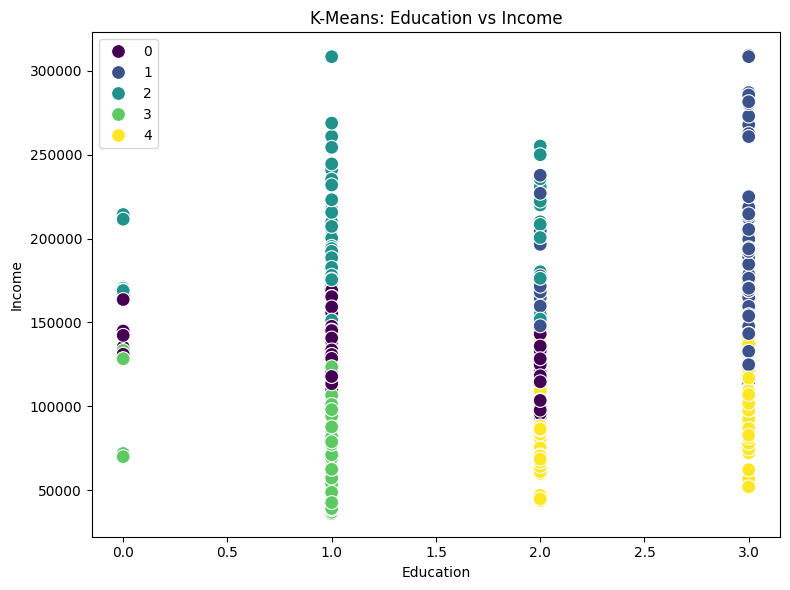

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X["Education"], y=X["Income"], hue=kmeans.labels_, palette='viridis', s=100)
plt.title("K-Means: Education vs Income")
plt.xlabel("Education")
plt.ylabel("Income")
plt.tight_layout()
plt.show()

**Hierarchical Clustering**

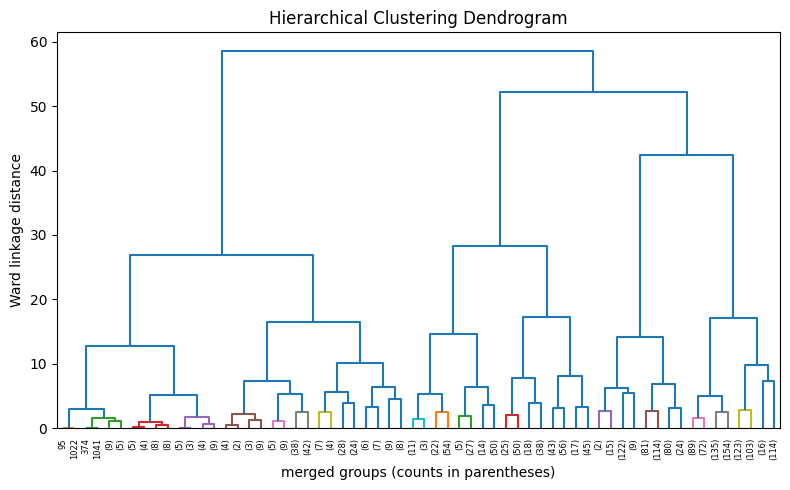

In [23]:
linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(8, 5))
dendrogram(linked, truncate_mode='level', p=5, color_threshold=3)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("merged groups (counts in parentheses)")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()